# Feature Stability

**Question:** with capacity for two teachers but three alternating, do some hidden units keep serving one task while others change at every switch?

Same teachers and learner as 01a: LTUs that fire on about 20% of inputs, and 20 hidden units. The three teachers alternate 1 → 2 → 3 → 1 → …, switching every 10k steps, for 2M steps. 30 seeds; the hidden-unit plots show seed 0.
- SGD with step size $2^{-6}$.
- Autostep + standardization.
- Baseline: Autostep + standardization with 12 of its 20 hidden units frozen as true LTUs, 4 from each teacher (the rows above the black line).

The learning curve shows the first and last 80k steps: the mean over seeds with a 95% confidence band. The hidden-unit plot has one row per hidden unit over the last 10 task switches, from snapshots every 1k steps; the strip on top shows the active task.

**Closest teacher LTU.** The color is the teacher of the LTU whose firing has the largest |correlation| with the unit's firing on 1000 fixed random inputs, and its strength is that |correlation|.

In [1]:
from functools import partial
from typing import NamedTuple

import jax
jax.config.update('jax_platforms', 'cuda')
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np

from phd.jax_core.models import ltu
from phd.jax_core.optimizers.idbd import optax_idbd

%matplotlib inline
assert jax.default_backend() == 'gpu'

/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/home/edan/miniconda3/envs/jax/lib/python3.10/site-packages/pydantic/_internal/_generate_schema.py:2274: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an 

In [2]:
# Problem
N_INPUTS, WIDTH, N_OUTPUTS = 21, 10, 10
N_TASKS = 3
THRESHOLD = 4  # teacher LTUs fire on about 20% of inputs
N_HIDDEN = 2 * WIDTH  # capacity for two teachers

# Schedule
PERIOD = 10_000  # steps before switching to the next teacher
STEPS = 2_000_000
WINDOW = 1000
FLIPS = 10  # task switches shown in the hidden-unit plots
PLOT_STEPS = 80_000  # steps shown at the start and end of the learning curve

# Methods
SGD_RATE = 2. ** -6
INIT_RATE, META_RATE, EMA_RATE = np.exp(-8.), 0.02, 1e-3
VAR_FLOOR = .01
GIVEN = 4  # baseline: frozen true LTUs per teacher
N_SEEDS = 30
SEED = 0  # seed shown in the hidden-unit plots
PROBE = jnp.asarray(np.random.default_rng(0).choice([-1., 1.], (1000, N_INPUTS)), dtype=jnp.float32)

In [3]:
def init_teacher(key):
    input_key, output_key = jax.random.split(key)
    w = jax.random.rademacher(input_key, (WIDTH, N_INPUTS), dtype=jnp.float32)
    v = jax.random.rademacher(output_key, (N_OUTPUTS, WIDTH), dtype=jnp.float32)
    return w, v


def target(teacher, x):
    w, v = teacher
    return v @ (w @ x > THRESHOLD).astype(jnp.float32)


def teachers_for(seed):
    teacher_key = jax.random.split(jax.random.PRNGKey(seed), 3)[0]
    return jax.vmap(init_teacher)(jax.random.split(teacher_key, N_TASKS))

In [4]:
OPTIMIZER = optax_idbd(meta_lr=META_RATE, init_lr=INIT_RATE, autostep=True, tau=1e4, version='squared_inputs')


class Learner(NamedTuple):
    weights: tuple  # hidden (unit, input + bias), readout (output, unit + bias)
    opt: object
    mean: jax.Array  # running mean of each hidden unit
    slope: jax.Array  # running mean of sigma'(z) x
    cov: jax.Array  # running covariance of the unit with sigma'(z) x


def init_learner(key, method):
    bound = INIT_RATE if method == 'Autostep' else np.sqrt(3 / N_INPUTS)
    hidden = jax.random.uniform(key, (N_HIDDEN, N_INPUTS + 1), minval=-bound, maxval=bound).at[:, -1].set(0.)
    weights = (hidden, jnp.zeros((N_OUTPUTS, N_HIDDEN + 1)))
    return Learner(weights, OPTIMIZER.init(weights) if method == 'Autostep' else None,
                   jnp.full(N_HIDDEN, .5), jnp.zeros_like(hidden).at[:, -1].set(.25), jnp.zeros_like(hidden))


def forward(weights, x, learner, method):
    source = jnp.append(x, 1.)
    z = weights[0] @ source
    h = ltu(z)
    mean, slope, cov = learner.mean, learner.slope, learner.cov
    if method == 'Autostep':
        # Standardization: center and divide by the running standard deviation, with the backward pass accounting
        # for how the mean and the standard deviation change with the input weights.
        mean = mean + EMA_RATE * (jax.lax.stop_gradient(h) - mean)
        sigmoid = jax.nn.sigmoid(z)
        derivative = jax.lax.stop_gradient(sigmoid * (1 - sigmoid))[:, None] * source
        slope = slope + EMA_RATE * (derivative - slope)
        correction = jnp.sum(slope * weights[0], axis=1)
        centered = jax.lax.stop_gradient(h - mean)
        h = h - mean + (jax.lax.stop_gradient(correction) - correction)
        cov = cov + EMA_RATE * (centered[:, None] * (derivative - slope) - cov)
        var = mean * (1 - mean)
        change = jnp.sum(cov * weights[0], axis=1)
        floored = jnp.maximum(var, VAR_FLOOR)
        h = (h - centered * jnp.where(var > VAR_FLOOR, (change - jax.lax.stop_gradient(change)) / floored, 0.)) / jnp.sqrt(floored)
    hidden = jnp.append(h, 1.)
    return weights[1] @ hidden, ((source[None], hidden[None]), mean, slope, cov)


def update(learner, x, y, method, frozen):
    def loss(weights):
        prediction, aux = forward(weights, x, learner, method)
        return .5 * jnp.sum((prediction - y) ** 2), aux
    (loss_value, (sources, mean, slope, cov)), grads = jax.value_and_grad(loss, has_aux=True)(learner.weights)
    if method == 'Autostep':
        updates, opt = OPTIMIZER.update((grads, None, sources), learner.opt, learner.weights)
    else:
        updates, opt = jax.tree.map(lambda g: -SGD_RATE * g, grads), None
    updates = (updates[0] * ~frozen[:, None], updates[1])
    return Learner(jax.tree.map(jnp.add, learner.weights, updates), opt, mean, slope, cov), 2 * loss_value / N_OUTPUTS

In [5]:
def train(seed, method, given):
    learner_key, rng = jax.random.split(jax.random.PRNGKey(seed), 3)[1:]
    teachers = teachers_for(seed)
    learner = init_learner(learner_key, method)
    # Baseline: the first hidden units are frozen copies of the first `given` LTUs of each teacher.
    frozen = jnp.arange(N_HIDDEN) < N_TASKS * given
    true = jnp.pad(teachers[0][:, :given].reshape(-1, N_INPUTS), ((0, N_HIDDEN - N_TASKS * given), (0, 0)))
    true = jnp.append(true, jnp.full((N_HIDDEN, 1), -THRESHOLD), axis=1)
    learner = learner._replace(weights=(jnp.where(frozen[:, None], true, learner.weights[0]), learner.weights[1]))

    def block(carry, block_id):
        teacher = jax.tree.map(lambda w: w[block_id % N_TASKS], teachers)

        def sample(carry, _):
            learner, rng = carry
            rng, x_key, noise_key = jax.random.split(rng, 3)
            x = jax.random.rademacher(x_key, (N_INPUTS,), dtype=jnp.float32)
            y = target(teacher, x) + jax.random.normal(noise_key, (N_OUTPUTS,))
            learner, mse = update(learner, x, y, method, frozen)
            return (learner, rng), mse

        def record(carry, _):
            carry, mse = jax.lax.scan(sample, carry, length=WINDOW)
            return carry, (mse.mean(), carry[0].weights[0])
        return jax.lax.scan(record, carry, length=PERIOD // WINDOW)

    _, (mse, hidden) = jax.lax.scan(block, (learner, rng), jnp.arange(STEPS // PERIOD))
    # Window-mean MSE, and the hidden weights at the end of each window of the last FLIPS + 1 blocks.
    return mse.reshape(-1), hidden.reshape(-1, N_HIDDEN, N_INPUTS + 1)[-(FLIPS + 1) * PERIOD // WINDOW:]


@partial(jax.jit, static_argnames=('method', 'given'))
def run(method, given=0):
    return jax.vmap(partial(train, method=method, given=given))(jnp.arange(N_SEEDS))


runs = {}
for label, method, given in ((rf'SGD $2^{{-6}}$', 'SGD', 0), ('Autostep + standardization', 'Autostep', 0),
                             (f'Baseline: {GIVEN} frozen true features per task', 'Autostep', GIVEN)):
    mse, hidden = map(np.asarray, run(method, given))
    runs[label] = mse, hidden, N_TASKS * given

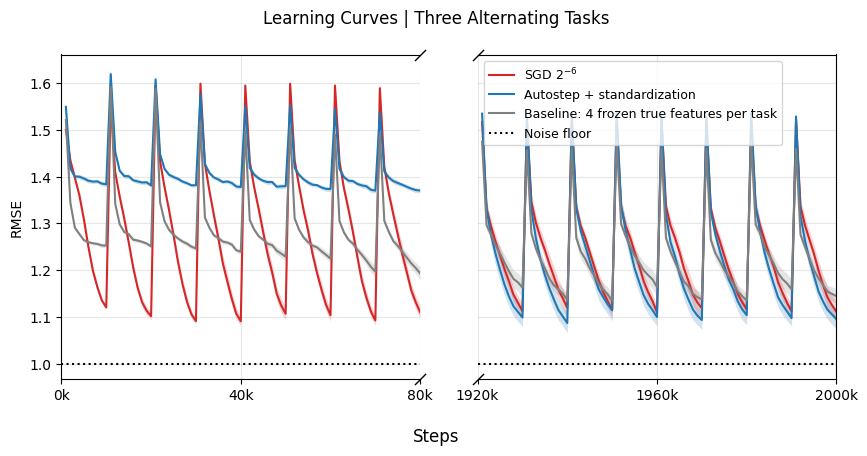

In [6]:
x = np.arange(1, STEPS // WINDOW + 1) * WINDOW
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True, gridspec_kw={'wspace': .16})
for ax, (left, right) in zip(axes, ((0, PLOT_STEPS), (STEPS - PLOT_STEPS, STEPS))):
    visible = (x > left) & (x <= right)
    for (label, (mse, _, _)), color in zip(runs.items(), ('C3', 'tab:blue', 'gray')):
        rmse = np.sqrt(mse[:, visible])
        mean, ci = rmse.mean(0), 1.96 * rmse.std(0) / np.sqrt(N_SEEDS)
        ax.plot(x[visible], mean, color=color, label=label)
        ax.fill_between(x[visible], mean - ci, mean + ci, color=color, alpha=.2, lw=0)
    ax.axhline(1, color='black', ls=':', label='Noise floor')
    ax.set_xlim(left, right)
    ticks = np.linspace(left, right, 3).astype(int)
    ax.set_xticks(ticks, [f'{t // 1000}k' for t in ticks])
    ax.grid(True, alpha=.3)
# Two diagonal dashes mark the time skip.
marks = dict(marker=[(-1, -1), (1, 1)], markersize=8, linestyle='none', color='black', clip_on=False)
axes[0].spines['right'].set_visible(False)
axes[0].plot([1, 1], [0, 1], transform=axes[0].transAxes, **marks)
axes[1].spines['left'].set_visible(False)
axes[1].tick_params(axis='y', left=False)
axes[1].plot([0, 0], [0, 1], transform=axes[1].transAxes, **marks)
axes[0].set_ylabel('RMSE')
axes[1].legend(fontsize=9)
fig.suptitle('Learning Curves | Three Alternating Tasks')
fig.supxlabel('Steps')
fig.subplots_adjust(bottom=.16)
plt.show()

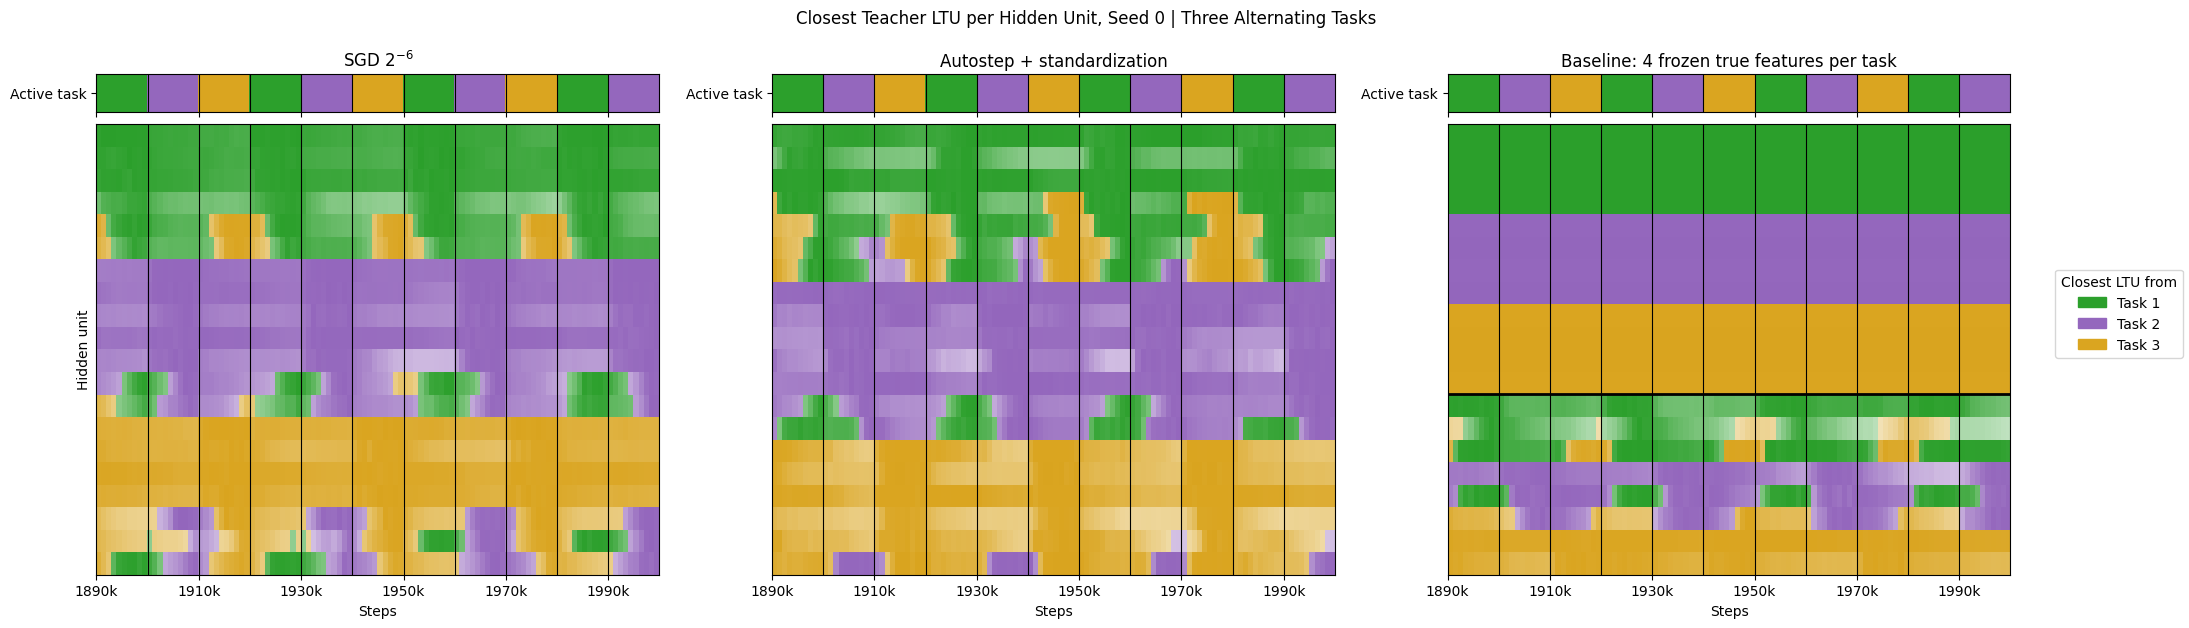

In [7]:
from matplotlib.colors import to_rgb
from matplotlib.patches import Patch

TASK_COLORS = np.array([to_rgb(c) for c in ('tab:green', 'tab:purple', 'goldenrod')])


def zscore(a):
    return (a - a.mean(-1, keepdims=True)) / (a.std(-1, keepdims=True) + 1e-8)


true_firing = np.asarray(teachers_for(SEED)[0].reshape(-1, N_INPUTS) @ PROBE.T > THRESHOLD, dtype=np.float32)  # (teacher LTU, probe)
start = STEPS - (FLIPS + 1) * PERIOD
fig, axes = plt.subplots(2, len(runs), figsize=(7 * len(runs) + 1, 6.5), sharex=True,
                         gridspec_kw={'height_ratios': (1, 12), 'hspace': .05})
for column, (label, (_, hidden, frozen)) in zip(axes.T, runs.items()):
    firing = (hidden[SEED] @ np.append(PROBE, np.ones((len(PROBE), 1)), axis=1).T > 0).astype(np.float32)
    correlation = np.abs(zscore(firing) @ zscore(true_firing).T) / len(PROBE)  # (snapshot, unit, teacher LTU)
    task, strength = correlation.argmax(-1) // WIDTH, correlation.max(-1)
    image = 1 - strength[..., None] * (1 - TASK_COLORS[task])
    # Frozen units first, then units grouped by the task they are most often closest to.
    counts = np.stack([(task == t).sum(0) for t in range(N_TASKS)], -1)
    order = np.lexsort((-counts.max(-1), counts.argmax(-1), (np.arange(N_HIDDEN) >= frozen).astype(int)))
    column[1].imshow(image[:, order].transpose(1, 0, 2), aspect='auto', interpolation='nearest',
                     extent=(start, STEPS, N_HIDDEN, 0))
    if frozen:
        column[1].axhline(frozen, color='black', lw=2)
    column[0].imshow(TASK_COLORS[np.arange(STEPS // PERIOD - FLIPS - 1, STEPS // PERIOD) % N_TASKS][None], aspect='auto',
                     extent=(start, STEPS, 0, 1))
    for ax in column:
        for flip in range(start + PERIOD, STEPS, PERIOD):
            ax.axvline(flip, color='black', lw=.8)
    column[0].set_title(label)
    column[0].set_yticks([.5], ['Active task'])
    column[1].set_yticks([])
    column[1].set_xticks(range(start, STEPS + 1, 2 * PERIOD), [f'{t // 1000}k' for t in range(start, STEPS + 1, 2 * PERIOD)])
    column[1].set_xlabel('Steps')
axes[1, 0].set_ylabel('Hidden unit')
fig.legend(handles=[Patch(color=c, label=f'Task {t + 1}') for t, c in enumerate(TASK_COLORS)], loc='center right',
           title='Closest LTU from')
fig.suptitle(f'Closest Teacher LTU per Hidden Unit, Seed {SEED} | Three Alternating Tasks')
fig.subplots_adjust(left=.05, right=.92)
plt.show()